# 03 — Features & Modelling

Builds features (`src/features.py`), tunes 4 model families + 2 baselines with time-ordered CV, selects on validation, evaluates **once** on the test years, runs the storm-weighting ablation, and saves the production model.

| Split | Years | Role |
|---|---|---|
| train | 1998–2016 | fitting + `TimeSeriesSplit(5)` CV tuning |
| validation | 2017–2019 | model selection (note: solar minimum) |
| test | 2020–2026-01 | single final evaluation (includes May 2024 storm) |

Uses the **final (v3)** setup decided in `05_final_round.ipynb` (storm memory / monotonic constraints per `src/config.py`) plus a conformal interval calibration. v1 and v2 results are archived in `reports/v1/` and `reports/v2/`. An equal-weight ensemble (HistGB + RF + SVR) is reported alongside the single models.

**Run with kernel "Python 3.12 (tormenta)".** Full run ≈ 30–60 min on this laptop; set `FAST = True` for a ~2-minute smoke test (results not meaningful). Close other heavy apps first.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, train, evaluate as ev
from src.features import derived
from src.predict import predict_with_interval
from src.preprocessing import load_processed

FAST = False          # True = quick smoke test only
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

## 1. Features
One call to the shared `build_features` — the same function the live apps use.

In [2]:
X, y, persistence = train.load_xy()
masks = train.split_masks(X.index)

print(f"{X.shape[1]} features | storm memory: {config.USE_MEMORY_FEATURES} | "
      f"monotonic constraints: {config.USE_MONOTONIC}")
print({k: f"{v.sum():,} hours" for k, v in masks.items()})
groups = {
    "raw": config.SW_FEATURES,
    "derived": ["pressure", "efield", "vbs", "beta", "mach_a", "bt", "sin_half_clock", "newell"],
    "lags": [c for c in X if "_lag" in c],
    "rolling": [c for c in X if any(s in c for s in ("_mean", "_std", "_min", "_max"))
                and not c.startswith("f107") and "_block_" not in c],
    "block so far": [c for c in X if c == "block_hour" or "_block_" in c],
    "storm memory": [c for c in X if "_decay" in c],
    "F10.7": [c for c in X if c.startswith("f107")],
    "time": [c for c in X if c.startswith(("hour_", "doy_"))],
}
groups["other"] = [c for c in X if not any(c in g for g in groups.values())]
pd.DataFrame({"count": {g: len(c) for g, c in groups.items()}, "columns": {g: ", ".join(c) for g, c in groups.items()}})

66 features | storm memory: False | monotonic constraints: False
{'train': '166,560 hours', 'val': '26,280 hours', 'test': '52,848 hours'}


,count,columns
raw,7,"b_scalar, bx, by_gsm, bz_gsm, temperature, den..."
derived,8,"pressure, efield, vbs, beta, mach_a, bt, sin_h..."
lags,16,"bz_gsm_lag1h, bz_gsm_lag3h, bz_gsm_lag6h, bz_g..."
rolling,23,"bz_gsm_mean3h, bz_gsm_std3h, speed_mean3h, spe..."
block so far,5,"block_hour, newell_block_mean, vbs_block_mean,..."
storm memory,0,
F10.7,2,"f107_prev, f107_mean81d"
time,4,"hour_sin, hour_cos, doy_sin, doy_cos"
other,1,pressure_change1h


### 1b. Check: our recomputed physics vs OMNI's own columns
β and Alfvén Mach use OMNI's formulas, so they should match closely. Our pressure omits the alpha-particle term (SWPC has no alpha data), so expect a near-constant ratio. After this check OMNI's columns are never used again.

In [3]:
raw = load_processed()
sample = raw.loc["2005":"2006"].dropna()
d = derived(sample[config.SW_FEATURES])
check = pd.DataFrame({
    "ours / OMNI (median)": [(d[a] / sample[b]).median() for a, b in
                             [("pressure", "omni_pressure"), ("efield", "omni_efield"),
                              ("beta", "omni_beta"), ("mach_a", "omni_mach_a")]],
    "correlation": [d[a].corr(sample[b]) for a, b in
                    [("pressure", "omni_pressure"), ("efield", "omni_efield"),
                     ("beta", "omni_beta"), ("mach_a", "omni_mach_a")]],
}, index=["pressure", "efield", "beta", "mach_a"])
check

,ours / OMNI (median),correlation
pressure,0.876,0.989
efield,1.000,1.000
beta,1.000,1.000
mach_a,1.000,1.000


## 2. Tuning (CV within the training years)
`RandomizedSearchCV` + `TimeSeriesSplit(5)` → each fold trains on the past and validates on the future. KNN/SVR use every 9th hour (kernel SVR is O(n²–n³)); RF is tuned on every 3rd hour and refit on all.

In [ ]:
tuned = train.tune_models(X, y, masks, fast=FAST)

Linear Regression  CV RMSE 0.665  (   12 s)  {}
KNN                CV RMSE 0.696  (   10 s)  {'model__weights': 'distance', 'model__n_neighbors': 20}
SVR                CV RMSE 0.618  (  123 s)  {'model__C': np.float64(4.618448518326193), 'model__epsilon': 0.1, 'model__gamma': np.float64(0.005184641432105231)}


### 2b. Interval calibration (conformal)
The q10–q90 band was slightly too narrow (v2 test coverage 75.7%). CQR measures how far observed Kp falls outside the band on data the quantile models did not train on (out-of-fold CV years + validation years; never test or the gate holdout) and adds one margin to both sides so that coverage is 80% there.

In [ ]:
margin, cal = train.conformal_margin(tuned["HistGB"]["best_params"], X, y, masks, fast=FAST)
cal.to_csv(config.METRICS_DIR / "conformal_calibration.csv")
print(f"conformal margin: {margin:+.3f} Kp")
cal

## 3. Validation: model selection + over/under-fitting
`train_rmse` ≪ `cv_rmse` signals overfitting; all three high and similar signals underfitting. Validation (2017–2019) is solar minimum, so we read **CV RMSE, validation RMSE and storm RMSE together**.

In [ ]:
val_table = train.validation_table(tuned, X, y, masks, persistence)
val_table.to_csv(config.METRICS_DIR / "validation.csv")
display(val_table.drop(columns="n"))
m = val_table.drop(index="Persistence (baseline)")
ev.plot_overfitting(m["train_rmse"], m["cv_rmse"], m["rmse"], "09_overfitting")
plt.show()

## 4. Test set — evaluated once
Each family is refit on train+val with its tuned settings.

In [ ]:
test_table, test_preds, test_models = train.test_evaluation(tuned, X, y, masks, persistence, fast=FAST)
test_table.to_csv(config.METRICS_DIR / "test.csv")
display(test_table.drop(columns="n"))
ev.plot_model_comparison(test_table, "Test 2020–2026", "10_model_comparison")
plt.show()

### v1 → v2 → v3 on test (HistGB)

In [ ]:
versions = {v: pd.read_csv(ROOT / "reports" / v / "metrics" / "test.csv", index_col=0).loc["HistGB"]
            for v in ["v1", "v2"]}
versions["v3 (this run)"] = test_table.loc["HistGB"]
pd.DataFrame(versions).T.drop(columns="n")

In [ ]:
y_test = y[masks["test"]]
levels = ev.error_by_level(y_test, test_preds)
levels.to_csv(config.METRICS_DIR / "test_error_by_level.csv")
display(levels)
ev.plot_error_by_level(levels, "11_error_by_level")
plt.show()
ev.plot_pred_vs_actual(y_test, test_preds["HistGB"], "HistGB (test)", "12_pred_vs_actual")
plt.show()

### Error by position inside the 3-h Kp block
The first hour of a block is hardest: the model has not yet seen the solar wind that drives the rest of that block.

In [ ]:
pos = ev.rmse_by_block_hour(y_test, {k: test_preds[k] for k in ["Persistence (baseline)", "HistGB"]})
pos.to_csv(config.METRICS_DIR / "test_block_hour.csv")
pos

## 5. Ablation: storm weighting (w = 1 + Kp/3)
Does up-weighting storm hours reduce storm under-prediction, and at what cost overall?

In [ ]:
abl_table, abl_preds = train.weighting_ablation(tuned["HistGB"]["best_params"], X, y, masks, fast=FAST)
abl_table.to_csv(config.METRICS_DIR / "ablation_weighting.csv")
display(abl_table.drop(columns="n"))
ev.error_by_level(y_test, abl_preds)

## 6. What does the model rely on?
Permutation importance of the train-only HistGB on the validation years (how much RMSE worsens when one feature is shuffled).

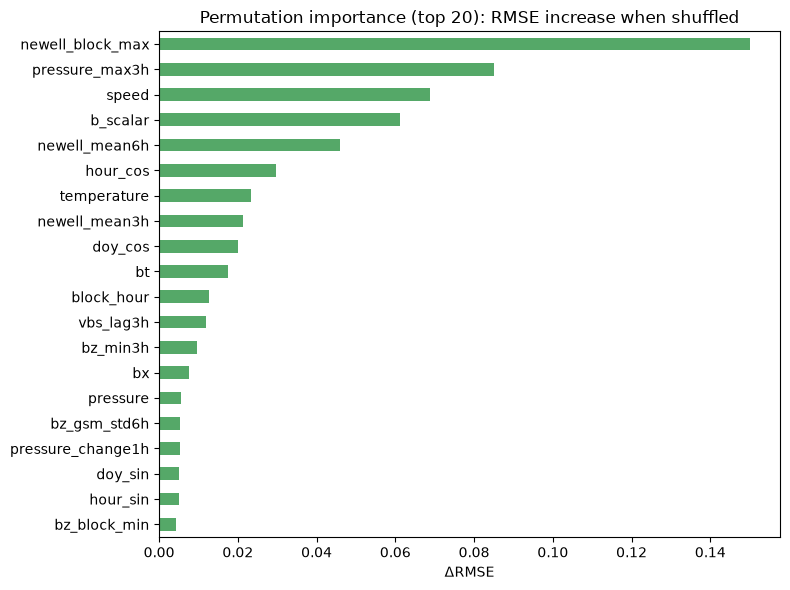

newell_block_max    0.150
pressure_max3h      0.085
speed               0.069
b_scalar            0.061
newell_mean6h       0.046
hour_cos            0.030
temperature         0.023
newell_mean3h       0.021
doy_cos             0.020
bt                  0.018
block_hour          0.013
vbs_lag3h           0.012
bz_min3h            0.009
bx                  0.008
pressure            0.006
dtype: float64

In [12]:
val = masks["val"]
_, importance = ev.plot_permutation_importance(tuned["HistGB"]["estimator"], X[val], y[val], "13_feature_importance")
plt.show()
importance.head(15).round(4)

## 7. Case study: May 2024 storm (model trained only on 1998–2019)

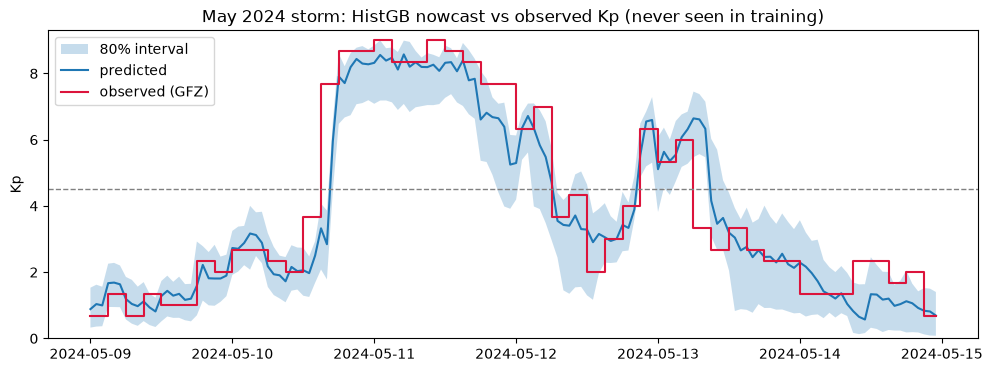

80% interval coverage on test: raw 75.7% → conformal 80.8%
mean interval width: raw 1.29 → conformal 1.41 Kp


In [13]:
case = train.fit_bundle(tuned["HistGB"]["best_params"], X, y, masks["train"] | masks["val"], fast=FAST,
                        margin=margin)
band = predict_with_interval(case, X[masks["test"]])
ev.plot_storm_case(y_test, band["kp_pred"], band["kp_lo"], band["kp_hi"], "2024-05-09", "2024-05-14",
                   "May 2024 storm: HistGB nowcast vs observed Kp (never seen in training)", "14_may2024_nowcast")
plt.show()
raw = predict_with_interval({**case, "interval_margin": 0.0}, X[masks["test"]])
cover = lambda b: ((y_test >= b["kp_lo"]) & (y_test <= b["kp_hi"])).mean()
print(f"80% interval coverage on test: raw {cover(raw):.1%} → conformal {cover(band):.1%}")
print(f"mean interval width: raw {(raw.kp_hi - raw.kp_lo).mean():.2f} → conformal {(band.kp_hi - band.kp_lo).mean():.2f} Kp")

## 8. Production model
HistGB (chosen for accuracy, small size, native NaN handling, quantile intervals) trained on all definitive data **up to the start of the last 6 months**; those 6 months are the validation-gate holdout that the weekly retrain will use. Saved as `models/tormenta_vYYYYMMDD.joblib` + `models/current.joblib`.

### Validation gate
The new model replaces the current one only if its RMSE on the holdout is ≤ 1.02 × the current model's — **both scored on the same 6 months, in this run**, and neither trained on them.

In [14]:
bundle, gate = train.fit_production(tuned["HistGB"]["best_params"], X, y, fast=FAST, margin=margin)
promote, incumbent = train.gate_decision(gate, X, y)
display(pd.DataFrame({"candidate (this run)": gate, "current model": incumbent or {}}))
if FAST:
    print("FAST mode: not saving the model.")
else:
    version = train.save_bundle(bundle, test_table.loc["HistGB"].to_dict(), gate, promote, incumbent)
    print(f"Saved {version} — promoted to current.joblib: {promote}")

,candidate (this run),current model
rmse,0.58,0.58
mae,0.456,0.456
r2,0.818,0.818
storm_rmse,0.695,0.695
storm_mae,0.554,0.554
n,4417,4417
coverage_80,0.82,0.774
holdout,2025-07-10 23:00:00 → 2026-01-10 23:00:00,2025-07-10 23:00:00 → 2026-01-10 23:00:00


Saved tormenta_v20261030_0737 — promoted to current.joblib: True
